# Makemore y Embeddings
Los embeddings son representaciones vectoriales de tokens.
https://www.jmlr.org/papers/volume3/bengio03a/bengio03a.pdf

In [85]:
import numpy as np
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
%matplotlib inline

In [86]:
#Abrimos el archivo con los nombres
dataset = open('../data/city_names_puny.txt', 'r').read().splitlines()
dataset[:8]

['heist-op-den-berg',
 'harchies',
 'florennes',
 'fleurus',
 'eugies',
 'eke',
 'dworp',
 'denderhoutem']

In [87]:
len(dataset)

143844

In [88]:
charset = ['*'] + sorted(list(set([y for x in dataset for y in x])))
ctoi = {c:i for i, c in enumerate(charset)}
itoc = {i:c for i, c in enumerate(charset)}
charset_len = len(charset)
print(ctoi)

{'*': 0, ' ': 1, '-': 2, '.': 3, '0': 4, '1': 5, '2': 6, '3': 7, '4': 8, '5': 9, '6': 10, '7': 11, '8': 12, '9': 13, 'a': 14, 'b': 15, 'c': 16, 'd': 17, 'e': 18, 'f': 19, 'g': 20, 'h': 21, 'i': 22, 'j': 23, 'k': 24, 'l': 25, 'm': 26, 'n': 27, 'o': 28, 'p': 29, 'q': 30, 'r': 31, 's': 32, 't': 33, 'u': 34, 'v': 35, 'w': 36, 'x': 37, 'y': 38, 'z': 39}


### Contrucción del dataset
Vamos a armar un dataset para entrenar la red neuronal un modelo similar al de Y. Bengio. El modelo mira 3 caracteres en el pasado y hace una predicción para 1 caracter en el futuro.

In [89]:
context_size = 3  # El tamaño del contexto o cuantos caracteres vamos a usar para predecir el siguiente
X, Y = [], []
for d in dataset[:5]:
    print(d)
    example = list(d) + ['*']
    context = [0] * context_size
    for c in example:
        print(''.join([itoc[x] for x in context]) + ' --> ' + c)
        X.append(context)
        Y.append(ctoi[c])
        context = context[1:] + [ctoi[c]]
X = torch.tensor(X)
Y = torch.tensor(Y)

heist-op-den-berg
*** --> h
**h --> e
*he --> i
hei --> s
eis --> t
ist --> -
st- --> o
t-o --> p
-op --> -
op- --> d
p-d --> e
-de --> n
den --> -
en- --> b
n-b --> e
-be --> r
ber --> g
erg --> *
harchies
*** --> h
**h --> a
*ha --> r
har --> c
arc --> h
rch --> i
chi --> e
hie --> s
ies --> *
florennes
*** --> f
**f --> l
*fl --> o
flo --> r
lor --> e
ore --> n
ren --> n
enn --> e
nne --> s
nes --> *
fleurus
*** --> f
**f --> l
*fl --> e
fle --> u
leu --> r
eur --> u
uru --> s
rus --> *
eugies
*** --> e
**e --> u
*eu --> g
eug --> i
ugi --> e
gie --> s
ies --> *


In [90]:
X.shape

torch.Size([52, 3])

### El modelo de NN de Bengio

In [91]:
g = torch.Generator().manual_seed(42)
emb_size = 2  # El número de dimensiones del Enbedding
C = torch.randn(charset_len, emb_size, generator=g)
emb = C[X]

In [92]:
emb.view((52,6))[0]

tensor([1.9269, 1.4873, 1.9269, 1.4873, 1.9269, 1.4873])

In [93]:
input_size = 6  # context size * emb_d
n_hidden = 128  # El número de neuronas en al capa hiddend que queremos
W1 = torch.randn(input_size, n_hidden, generator=g)
b1 = torch.randn(n_hidden, generator=g)

In [94]:
emb1 = emb.view(-1,input_size)
torch.tanh((emb1 @ W1) + b1)

tensor([[ 0.9998, -0.9978,  0.9852,  ...,  0.9998, -0.9752,  0.9999],
        [ 0.9816, -0.9991, -0.8815,  ...,  0.9129, -0.9989,  0.6509],
        [-0.9754, -0.9930, -0.9907,  ...,  1.0000,  0.9978,  0.8666],
        ...,
        [ 0.9902, -0.9296,  0.6414,  ...,  1.0000, -0.9519, -0.9932],
        [ 0.6679, -0.9957,  0.9705,  ...,  0.8060, -0.9986, -0.9975],
        [-0.1907, -0.9682,  0.9995,  ...,  0.9893, -0.9870,  0.9948]])

In [95]:

W2 = torch.randn(n_hidden, charset_len, generator=g)
b2 = torch.randn(charset_len, generator=g)

In [96]:
h = torch.tanh(emb.view(-1, input_size) @ W1 + b1)
logits = h @ W2 + b2

In [97]:
counts = logits.exp()
probs = counts / counts.sum(axis=1, keepdims=True)

In [98]:
loss = -probs[torch.arange(len(Y)), Y].log().mean()

In [99]:
loss

tensor(22.8729)

In [100]:
# Pasando en limpio
g = torch.Generator().manual_seed(42)
emb_size = 2  # El número de dimensiones del Enbedding
input_size = 6  # context size * emb_d
n_hidden = 128  # El número de neuronas en al capa hiddend que queremos

# Definición del modelo
C = torch.randn(charset_len, emb_size, generator=g)
W1 = torch.randn(input_size, n_hidden, generator=g)
b1 = torch.randn(n_hidden, generator=g)
W2 = torch.randn(n_hidden, charset_len, generator=g)
b2 = torch.randn(charset_len, generator=g)
parameters = [C, W1, b1, W2, b2]

In [101]:
sum(p.nelement() for p in parameters)

6136

In [102]:
for p in parameters:
    p.requires_grad = True

In [103]:
# forward pass con loss a mano
emb = C[X]
h = torch.tanh(emb.view(-1, input_size) @ W1 + b1)
logits = h @ W2 + b2
counts = logits.exp()
probs = counts / counts.sum(axis=1, keepdims=True)
loss = -probs[torch.arange(len(Y)), Y].log().mean()
loss

tensor(22.8729, grad_fn=<NegBackward0>)

In [104]:
F.cross_entropy(logits, Y)

tensor(22.8729, grad_fn=<NllLossBackward0>)

In [105]:
# forward pass usando F.cross_entropy
emb = C[X]
h = torch.tanh(emb.view(-1, input_size) @ W1 + b1)
logits = h @ W2 + b2
loss = F.cross_entropy(logits, Y)
loss

tensor(22.8729, grad_fn=<NllLossBackward0>)

In [106]:
# zero grad
for p in parameters:
    p.grad = None

# backward pass
loss.backward()

In [107]:
# update
for p in parameters:
    p.data += -0.1 * p.grad

In [108]:
loss

tensor(22.8729, grad_fn=<NllLossBackward0>)

In [109]:
for _ in range(1000):
    # forward pass usando F.cross_entropy
    emb = C[X]
    h = torch.tanh(emb.view(-1, input_size) @ W1 + b1)
    logits = h @ W2 + b2
    loss = F.cross_entropy(logits, Y)
    #print(loss.item())
    # backward pass
    for p in parameters:
        p.grad = None
    loss.backward()
    # update
    for p in parameters:
        p.data += -0.1 * p.grad
print(loss.item())

0.15903975069522858


In [110]:
# Inference
g = torch.Generator().manual_seed(42)

for i in range(10):
    context = [0] * context_size
    ix = 0
    out = []
    while True:
        emb = C[torch.tensor(context)]
        h = torch.tanh(emb.view(-1, input_size) @ W1 + b1)
        logits = h @ W2 + b2
        probs = F.softmax(logits,dim=1)
        ix = torch.multinomial(probs, num_samples=1, replacement=True, generator=g).item()
        context = context[1:] + [ix]
        out.append(itoc[ix])
        if ix == 0:
            break
    print(''.join(out[:-1]))

fleurus
eugies
eugies
fleurus
harchies
eugies
eugies
harchies
florennes
heist-op-den-berg


In [111]:
context_size = 3  # El tamaño del contexto o cuantos caracteres vamos a usar para predecir el siguiente
X, Y = [], []

for d in dataset:
    #print(d)
    example = list(d) + ['*']
    context = [0] * context_size
    for c in example:
        #print(''.join([itoc[x] for x in context]) + ' --> ' + c)
        X.append(context)
        Y.append(ctoi[c])
        context = context[1:] + [ctoi[c]]
X = torch.tensor(X)
Y = torch.tensor(Y)

In [146]:
# redefinimos el modelo...
g = torch.Generator().manual_seed(42)
emb_d = 2  # El número de dimensiones del Enbedding
input_size = 6  # context size * emb_d
n_hidden = 128  # El número de neuronas en al capa hiddend que queremos

# Definición del modelo
C = torch.randn(charset_len, emb_d, generator=g)
W1 = torch.randn(input_size, n_hidden, generator=g)
b1 = torch.randn(n_hidden, generator=g)
W2 = torch.randn(n_hidden, charset_len, generator=g)
b2 = torch.randn(charset_len, generator=g)
parameters = [C, W1, b1, W2, b2]
for p in parameters:
    p.requires_grad = True
sum(p.nelement() for p in parameters)

6136

In [113]:
C[X].shape

torch.Size([1737335, 3, 2])

In [157]:
minibatch_size = 1024
#loss_log = []
for _ in range(2000):
    # training loop en mini batches
    ix = torch.randint(0, len(X), (minibatch_size,))
    # forward pass usando F.cross_entropy
    emb = C[X[ix]]
    h = torch.tanh(emb.view(-1, input_size) @ W1 + b1)
    logits = h @ W2 + b2
    loss = F.cross_entropy(logits, Y[ix])
    loss_log.append(loss.item())
    # backward pass
    for p in parameters:
        p.grad = None
    loss.backward()
    # update
    for p in parameters:
        p.data += -0.01 * p.grad
print(loss.item())

2.7616219520568848


In [158]:
# Inference
g = torch.Generator().manual_seed(42)

for i in range(10):
    context = [0] * context_size
    ix = 0
    out = []
    while True:
        emb = C[torch.tensor(context)]
        h = torch.tanh(emb.view(-1, input_size) @ W1 + b1)
        logits = h @ W2 + b2
        probs = F.softmax(logits,dim=1)
        ix = torch.multinomial(probs, num_samples=1, replacement=True, generator=g).item()
        context = context[1:] + [ix]
        out.append(itoc[ix])
        if ix == 0:
            break
    print(''.join(out[:-1]))

xn--n-adsgat
cada
muita-bamve
xn--nuawynkegost
gol-
xn--jafto
phnnb
xn-linyuap bit0ien
uao
zenii-peanoce-de


In [121]:
-np.log(1/40)

np.float64(3.6888794541139363)

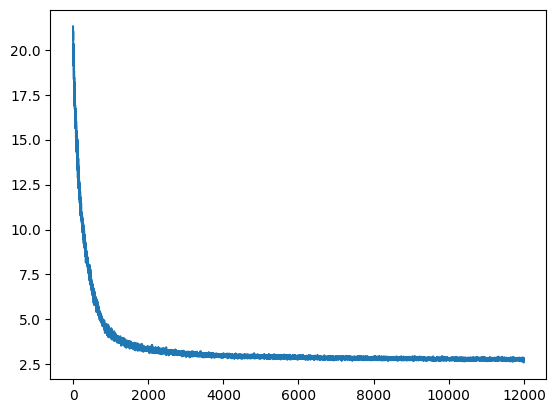

In [159]:
plt.plot(loss_log)
plt.show()

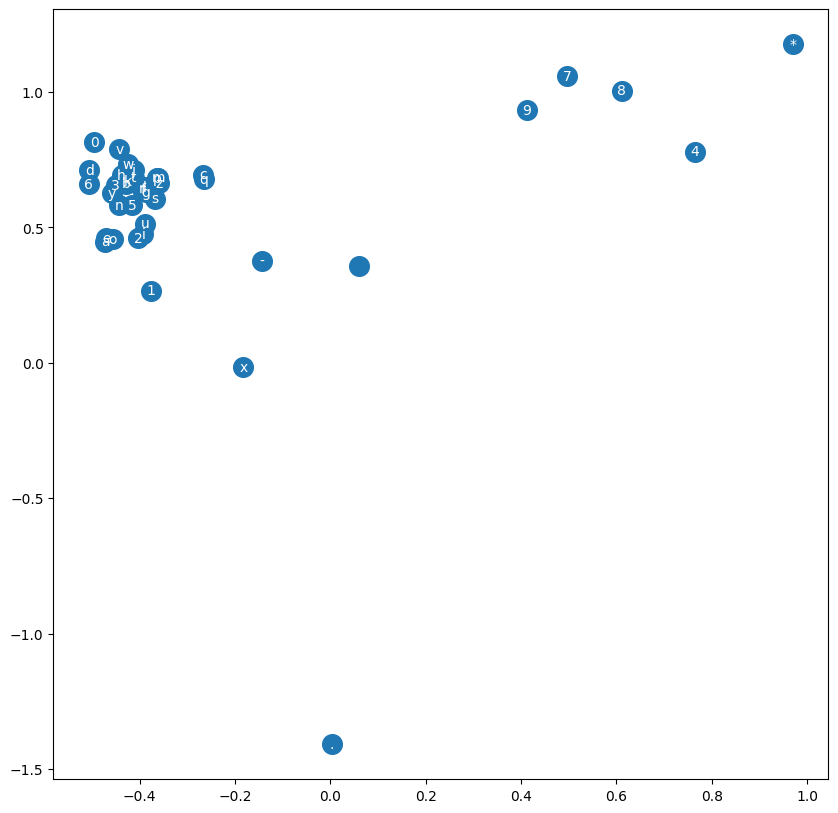

In [160]:
plt.figure(figsize=(10,10))
plt.scatter(C[:,0].data, C[:,1].data,s=200)
for i in range(C.shape[0]):
    plt.text(C[i,0].item(), C[i,1].item(), itoc[i], ha="center", va="center", color="white")
plt.show()